# Лабораторная работа №1 — вариант 5
**Двойной обратный маятник на тележке (нелинейная динамика)**

Ноутбук запускает все эксперименты (`experiments.py`) и показывает графики и таблицы. Код слоёв — в пакете `lab1/`: `perception.py`, `planning.py`, `control.py`, `failop.py`.

In [1]:
%run experiments.py

  -> fig0_architecture.png
Эксперимент 1: падение без контроллера
  -> fig1_baseline.png
Эксперимент 1b: чувствительность к начальным условиям


  -> fig2_chaos.png
Эксперимент 2: истина vs шум vs задержка
  -> fig3_perception.png
Эксперимент 3: одноконтурный PD vs LQR


  -> fig4_pd_vs_lqr.png
Эксперимент 4: частота управления


  -> fig5_frequency.png
Эксперимент 5: задержка измерений


  -> fig6_delay.png
Эксперимент 6: Fail-Operational


  -> fig7_failop.png
Эксперимент 7: область притяжения LQR


  -> fig8_roa.png
Эксперимент 8: время вычисления такта
Готово: results/results.json


In [2]:
import json
from IPython.display import Image, display
R = json.load(open('results/results.json', encoding='utf-8'))
def show(name):
    display(Image(filename=f'figures/{name}'))

## Архитектура: Perception → Planning → Control

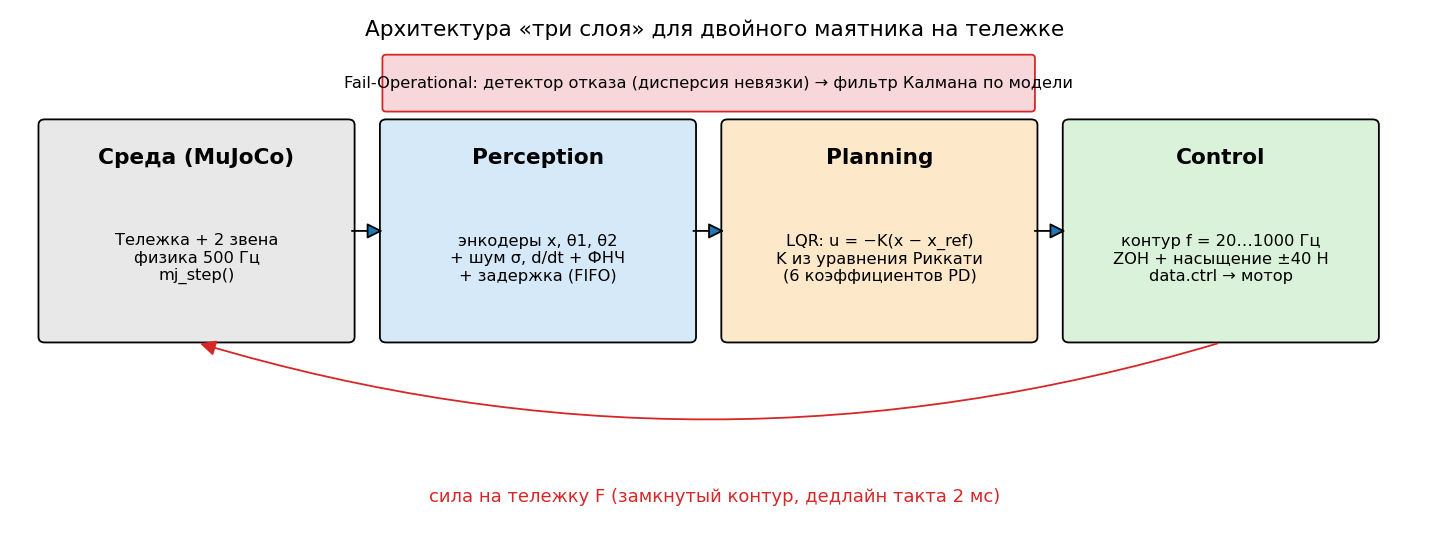

In [3]:
show('fig0_architecture.png')

## Часть 1. Без контроллера + нелинейность

Время падения без контроллера: 0.7020000000000001 с
Неустойчивые полюса, 1/с: [4.33449179130313, 9.287307850831587]


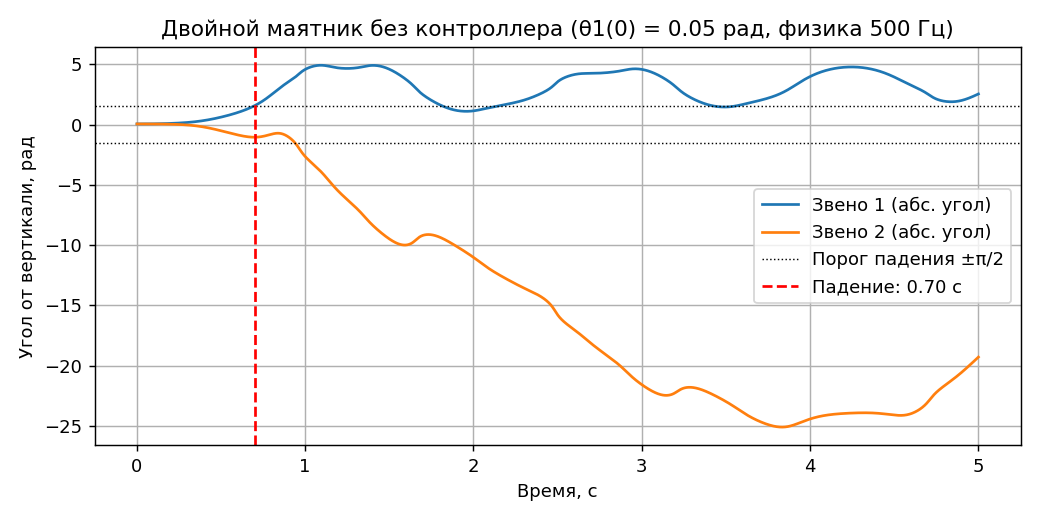

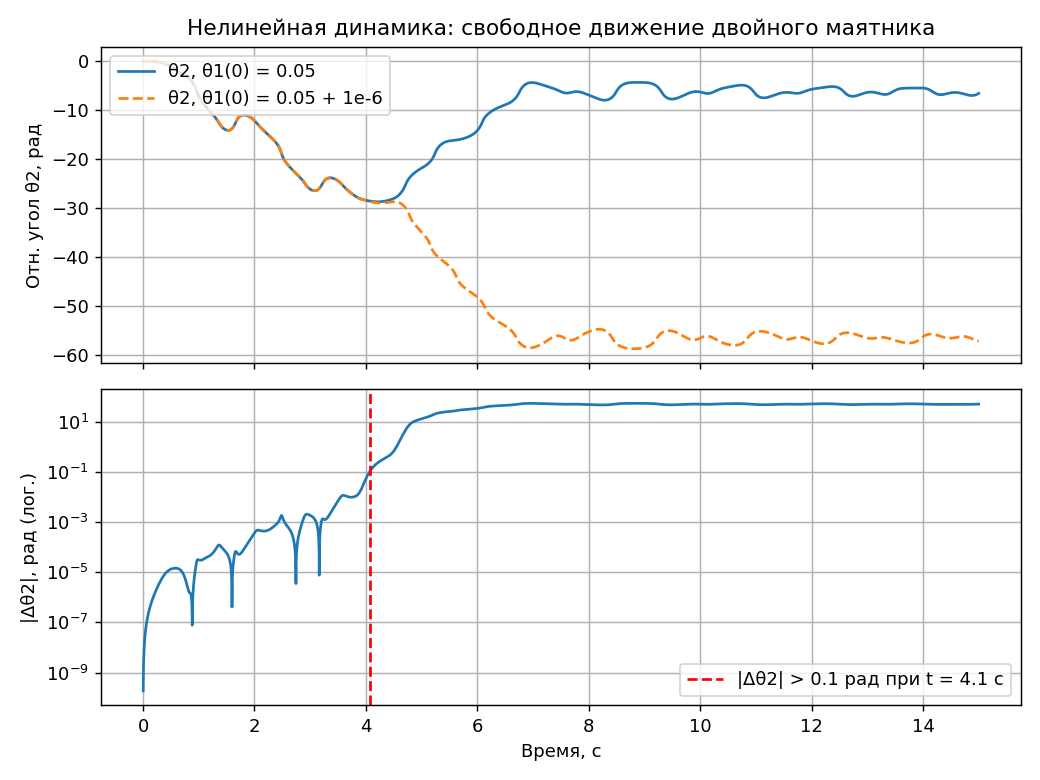

In [4]:
print('Время падения без контроллера:', R['baseline']['fall_time'], 'с')
print('Неустойчивые полюса, 1/с:', R['model']['unstable_eigs_continuous'])
show('fig1_baseline.png'); show('fig2_chaos.png')

## Часть 2–3. Perception и Planning (PD vs LQR)

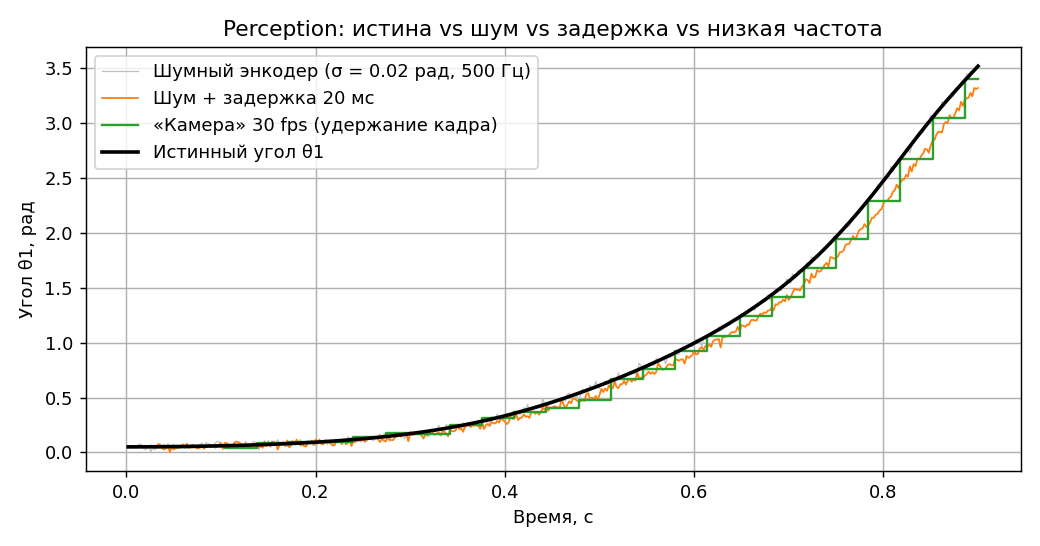

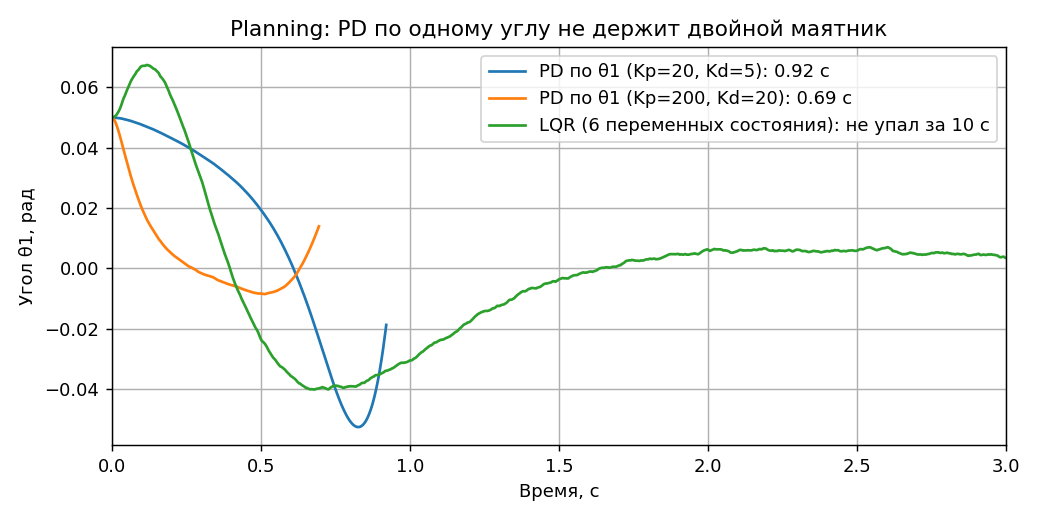

LQR K = [9.634, 85.242, 261.961, 14.23, 39.916, 37.025]


{'PD по θ1 (Kp=20, Kd=5)': 0.92,
 'PD по θ1 (Kp=200, Kd=20)': 0.6940000000000001,
 'LQR (6 переменных состояния)': None}

In [5]:
show('fig3_perception.png'); show('fig4_pd_vs_lqr.png')
print('LQR K =', R['model']['K_lqr_500'])
R['pd_vs_lqr']

## Часть 4. Частота управления

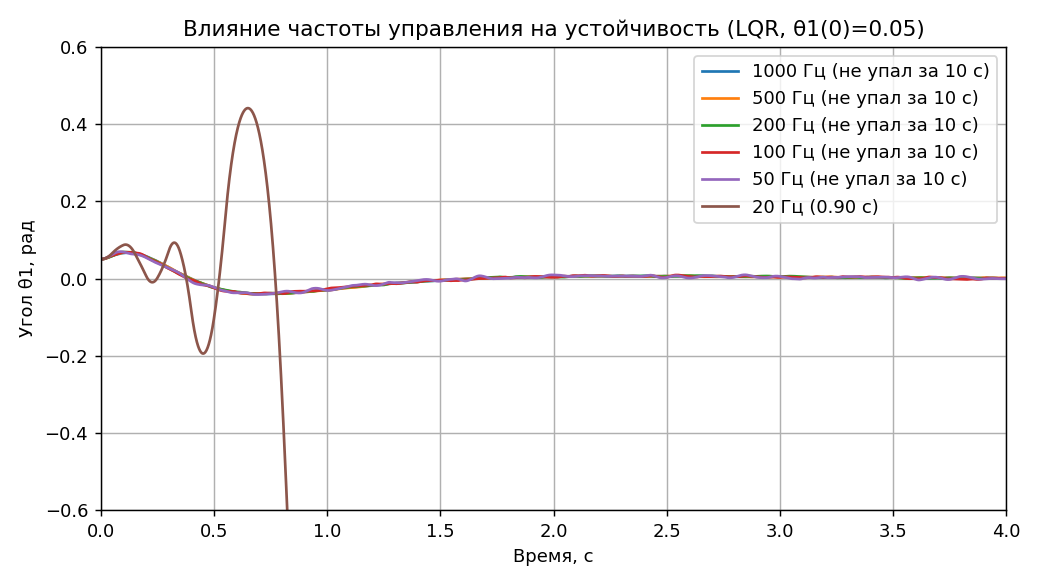

 1000 Гц  падение: None  устойчиво: True
  500 Гц  падение: None  устойчиво: True
  200 Гц  падение: None  устойчиво: True
  100 Гц  падение: None  устойчиво: True
   50 Гц  падение: None  устойчиво: True
   20 Гц  падение: 0.8999999999999999  устойчиво: False
Минимальная устойчивая частота: 24 Гц


In [6]:
show('fig5_frequency.png')
for r in R['frequency']['rows']:
    print(f"{r['freq']:>5} Гц  падение: {r['fall_time']}  устойчиво: {r['stable']}")
print('Минимальная устойчивая частота:', R['frequency']['min_stable_freq'], 'Гц')

## Часть 4.4. Задержка

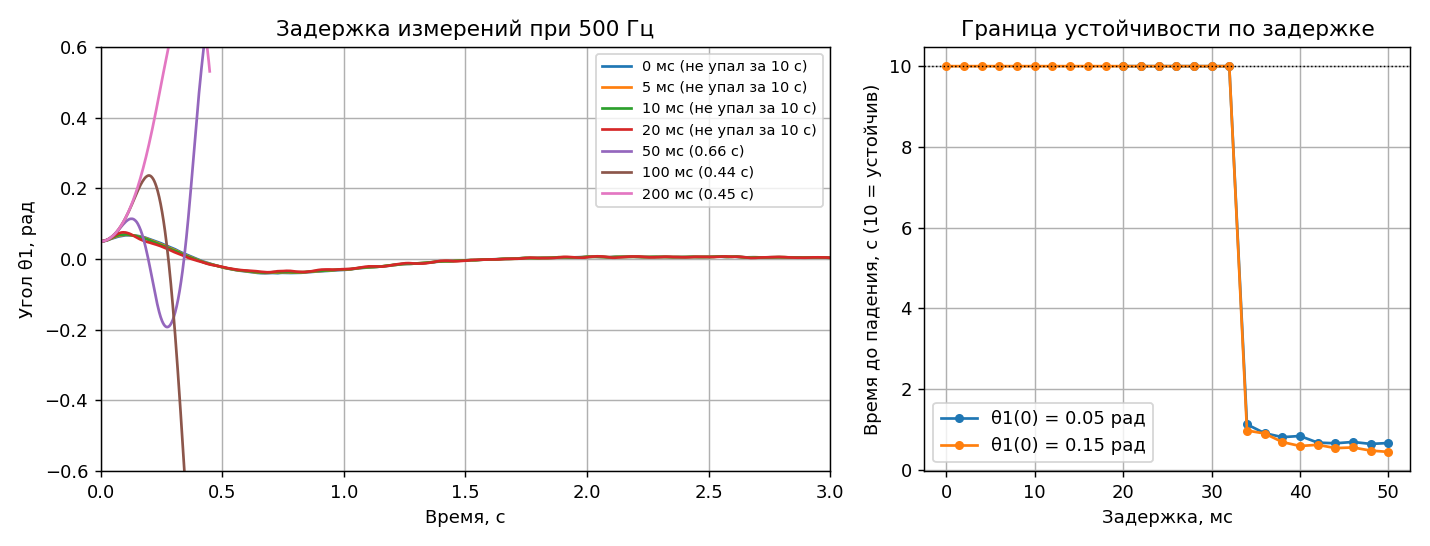

   0 мс  падение: None  устойчиво: True
   5 мс  падение: None  устойчиво: True
  10 мс  падение: None  устойчиво: True
  20 мс  падение: None  устойчиво: True
  50 мс  падение: 0.658  устойчиво: False
 100 мс  падение: 0.44  устойчиво: False
 200 мс  падение: 0.448  устойчиво: False
Граница: 32 мс устойчив, 34 мс падает


In [7]:
show('fig6_delay.png')
for r in R['delay']['rows']:
    print(f"{r['delay_ms']:>4} мс  падение: {r['fall_time']}  устойчиво: {r['stable']}")
print('Граница:', R['delay']['max_stable_delay_ms'], 'мс устойчив,', R['delay']['first_fail_delay_ms'], 'мс падает')

## Часть 5. Fail-Operational

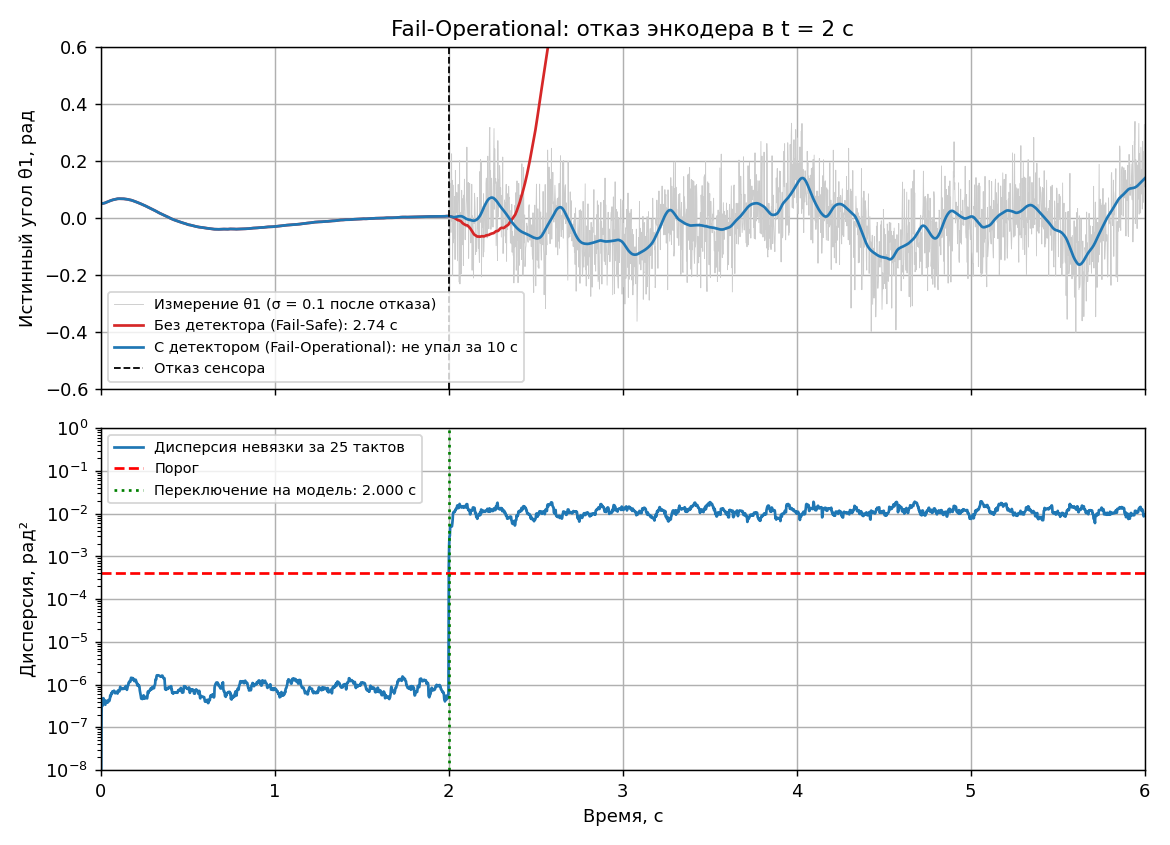

([{'detector': False,
   'falls': 10,
   'runs': 10,
   'mean_fall_time': 2.6422,
   'mean_time_after_fault': 0.6421999999999999,
   'max_theta_survived': None,
   'detect_delay_ms': None},
  {'detector': True,
   'falls': 0,
   'runs': 10,
   'mean_fall_time': None,
   'mean_time_after_fault': None,
   'max_theta_survived': 0.33220843434448777,
   'detect_delay_ms': 1.0000000000000675}],
 'ложных срабатываний: 0/10')

In [8]:
show('fig7_failop.png')
R['failop']['rows'], 'ложных срабатываний: %d/10' % R['failop']['false_alarms']

## Дополнительно: область притяжения и бюджет времени такта

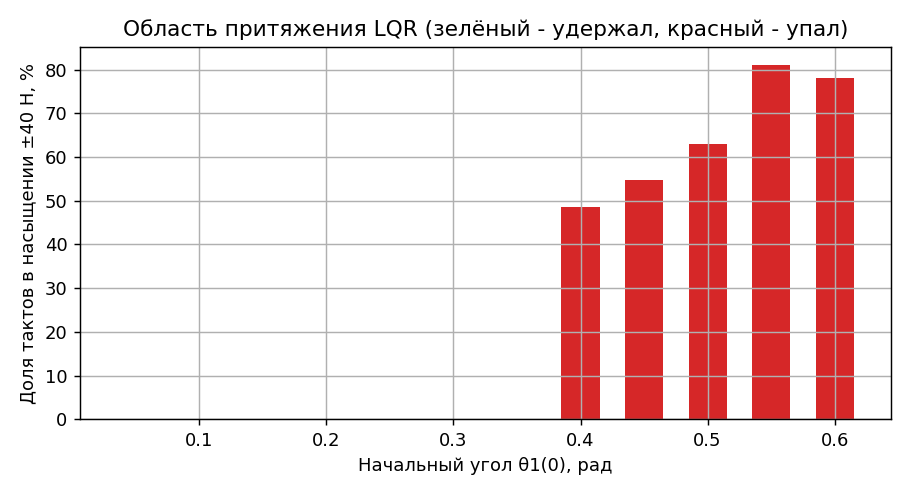

{'perception_planning_us': 14.71343999983219,
 'physics_step_us': 2.530540000225301,
 'deadline_us': 2000}

In [9]:
show('fig8_roa.png')
R['timing']